# Machine Learning Assignment 2
## Breast Cancer Wisconsin Diagnostic – Classification Models


## Stage 1 – Install and import libraries

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install --upgrade scipy seaborn

Note: you may need to restart the kernel to use updated packages.


In [5]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)

print("Libraries imported successfully.")


Libraries imported successfully.


## Stage 2 – Load and understand the dataset

In [7]:
data = load_breast_cancer(as_frame=True)
df = data.data.copy()
df["Diagnosis"] = data.target.map({0: "Malignant", 1: "Benign"})

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


In [8]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [9]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
display(df["Diagnosis"].value_counts())


Total missing values: 0
Duplicate rows: 0

Class distribution:


Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64

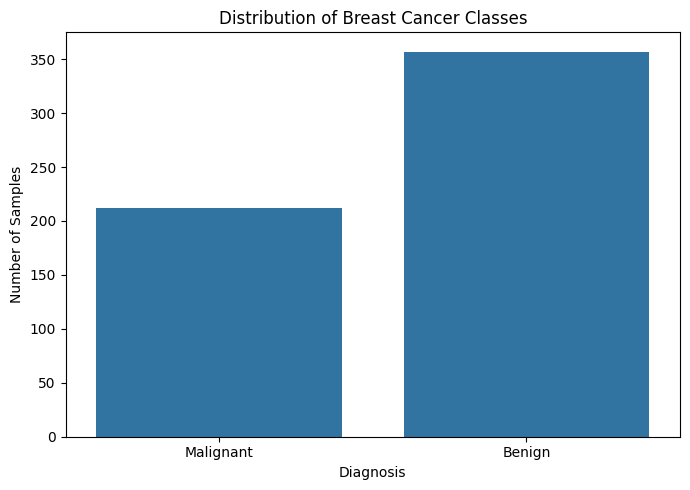

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Diagnosis")
plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


## Stage 3 – Separate features and target; split the data

In [12]:
X = df.drop(columns=["Diagnosis"])
y = df["Diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (569, 30)
Target shape: (569,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (455, 30)
Testing features: (114, 30)
Training target: (455,)
Testing target: (114,)


In [14]:
# Save the held-out test set, including the target column, for the Streamlit app.
test_data = X_test.copy()
test_data["Diagnosis"] = y_test
test_data.to_csv("test_data.csv", index=False)

print("test_data.csv saved.")
print("Test data shape:", test_data.shape)


test_data.csv saved.
Test data shape: (114, 31)


## Stage 4 – Define and train the five classification models

The same train/test split is used for all five models. Scaling is applied to Logistic Regression, KNN, and SVM. Decision Tree and Gaussian Naive Bayes are used without scaling.


In [16]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),
    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Naive Bayes": Pipeline([
        ("model", GaussianNB())
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=42))
    ])
}

print("Five classification models defined.")


Five classification models defined.


In [17]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")


Logistic Regression trained successfully.
Decision Tree trained successfully.
KNN trained successfully.
Naive Bayes trained successfully.
SVM trained successfully.


## Stage 5 – Calculate the six evaluation metrics

**Malignant** is treated as the positive class for Precision, Recall, F1-score, and AUC. AUC uses the predicted probability of the malignant class.


In [19]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    malignant_index = list(model.classes_).index("Malignant")
    y_prob_malignant = model.predict_proba(X_test)[:, malignant_index]
    y_test_binary = (y_test == "Malignant").astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test_binary, y_prob_malignant),
        "Precision": precision_score(y_test, y_pred, pos_label="Malignant", zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label="Malignant", zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, pos_label="Malignant", zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
print("Evaluation metrics calculated.")
display(results_df.round(4))


Evaluation metrics calculated.


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,SVM,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


## Stage 6 – Classification reports

In [21]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    print("\n" + "=" * 65)
    print("Model:", name)
    print("=" * 65)
    print(classification_report(
        y_test, y_pred,
        labels=["Benign", "Malignant"],
        zero_division=0
    ))



Model: Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


Model: Decision Tree
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        72
   Malignant       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114


Model: KNN
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg

## Stage 7 – Confusion matrices

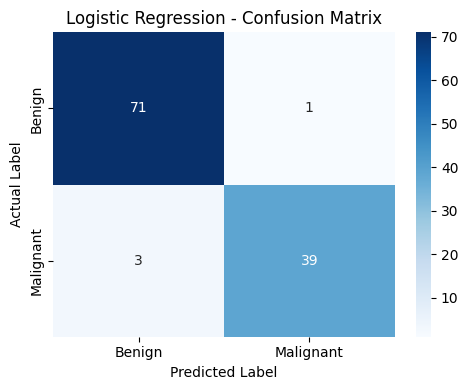

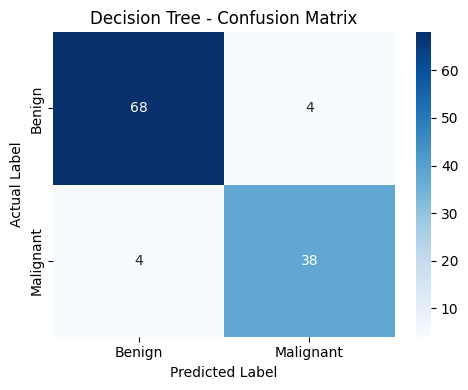

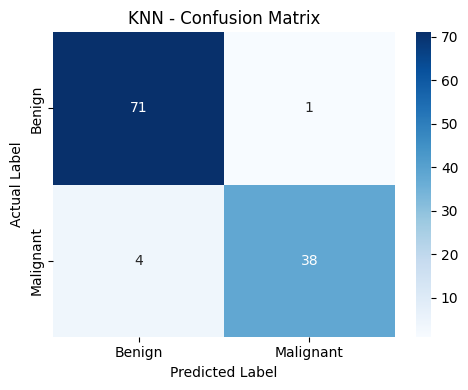

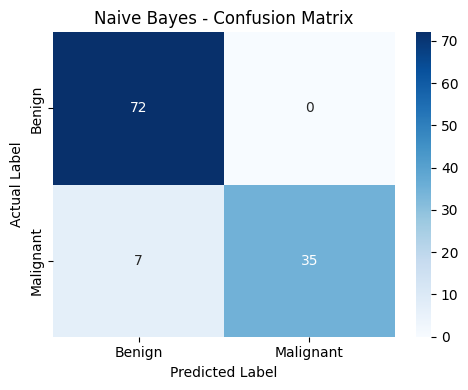

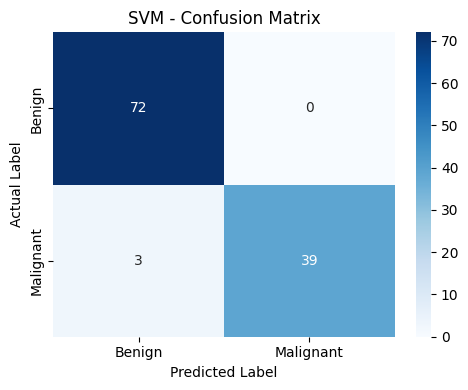

In [23]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=["Benign", "Malignant"])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"]
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()


## Stage 8 – Compare model accuracy

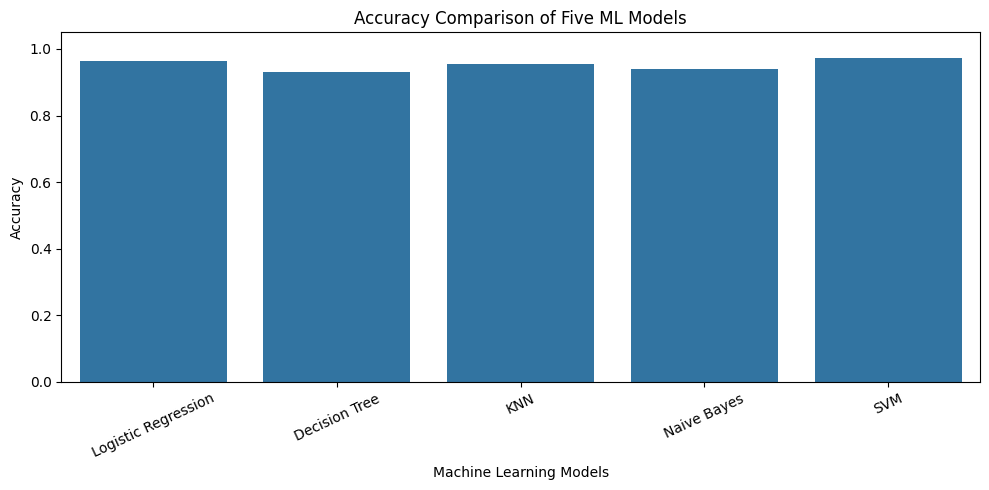

In [25]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.title("Accuracy Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=25)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


## Stage 9 – Identify the best model by F1-score

In [27]:
best_model_row = results_df.loc[results_df["F1 Score"].idxmax()]
print("Best-performing model by F1-score:")
display(best_model_row.to_frame(name="Value"))


Best-performing model by F1-score:


,Value
Model,SVM
Accuracy,0.973684
AUC,0.994709
Precision,1.0
Recall,0.928571
F1 Score,0.962963
MCC,0.944155


## Stage 10 – Save trained models and evaluation results

In [29]:
os.makedirs("model", exist_ok=True)

model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

for name, model in models.items():
    filepath = os.path.join("model", model_filenames[name])
    joblib.dump(model, filepath)
    print(f"Saved {name}: {filepath}")

results_df.to_csv("model_comparison.csv", index=False)
print("Saved model_comparison.csv")
print("Files in model directory:", sorted(os.listdir("model")))


Saved Logistic Regression: model/logistic_regression.joblib
Saved Decision Tree: model/decision_tree.joblib
Saved KNN: model/knn.joblib
Saved Naive Bayes: model/naive_bayes.joblib
Saved SVM: model/svm.joblib
Saved model_comparison.csv
Files in model directory: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'svm.joblib']
